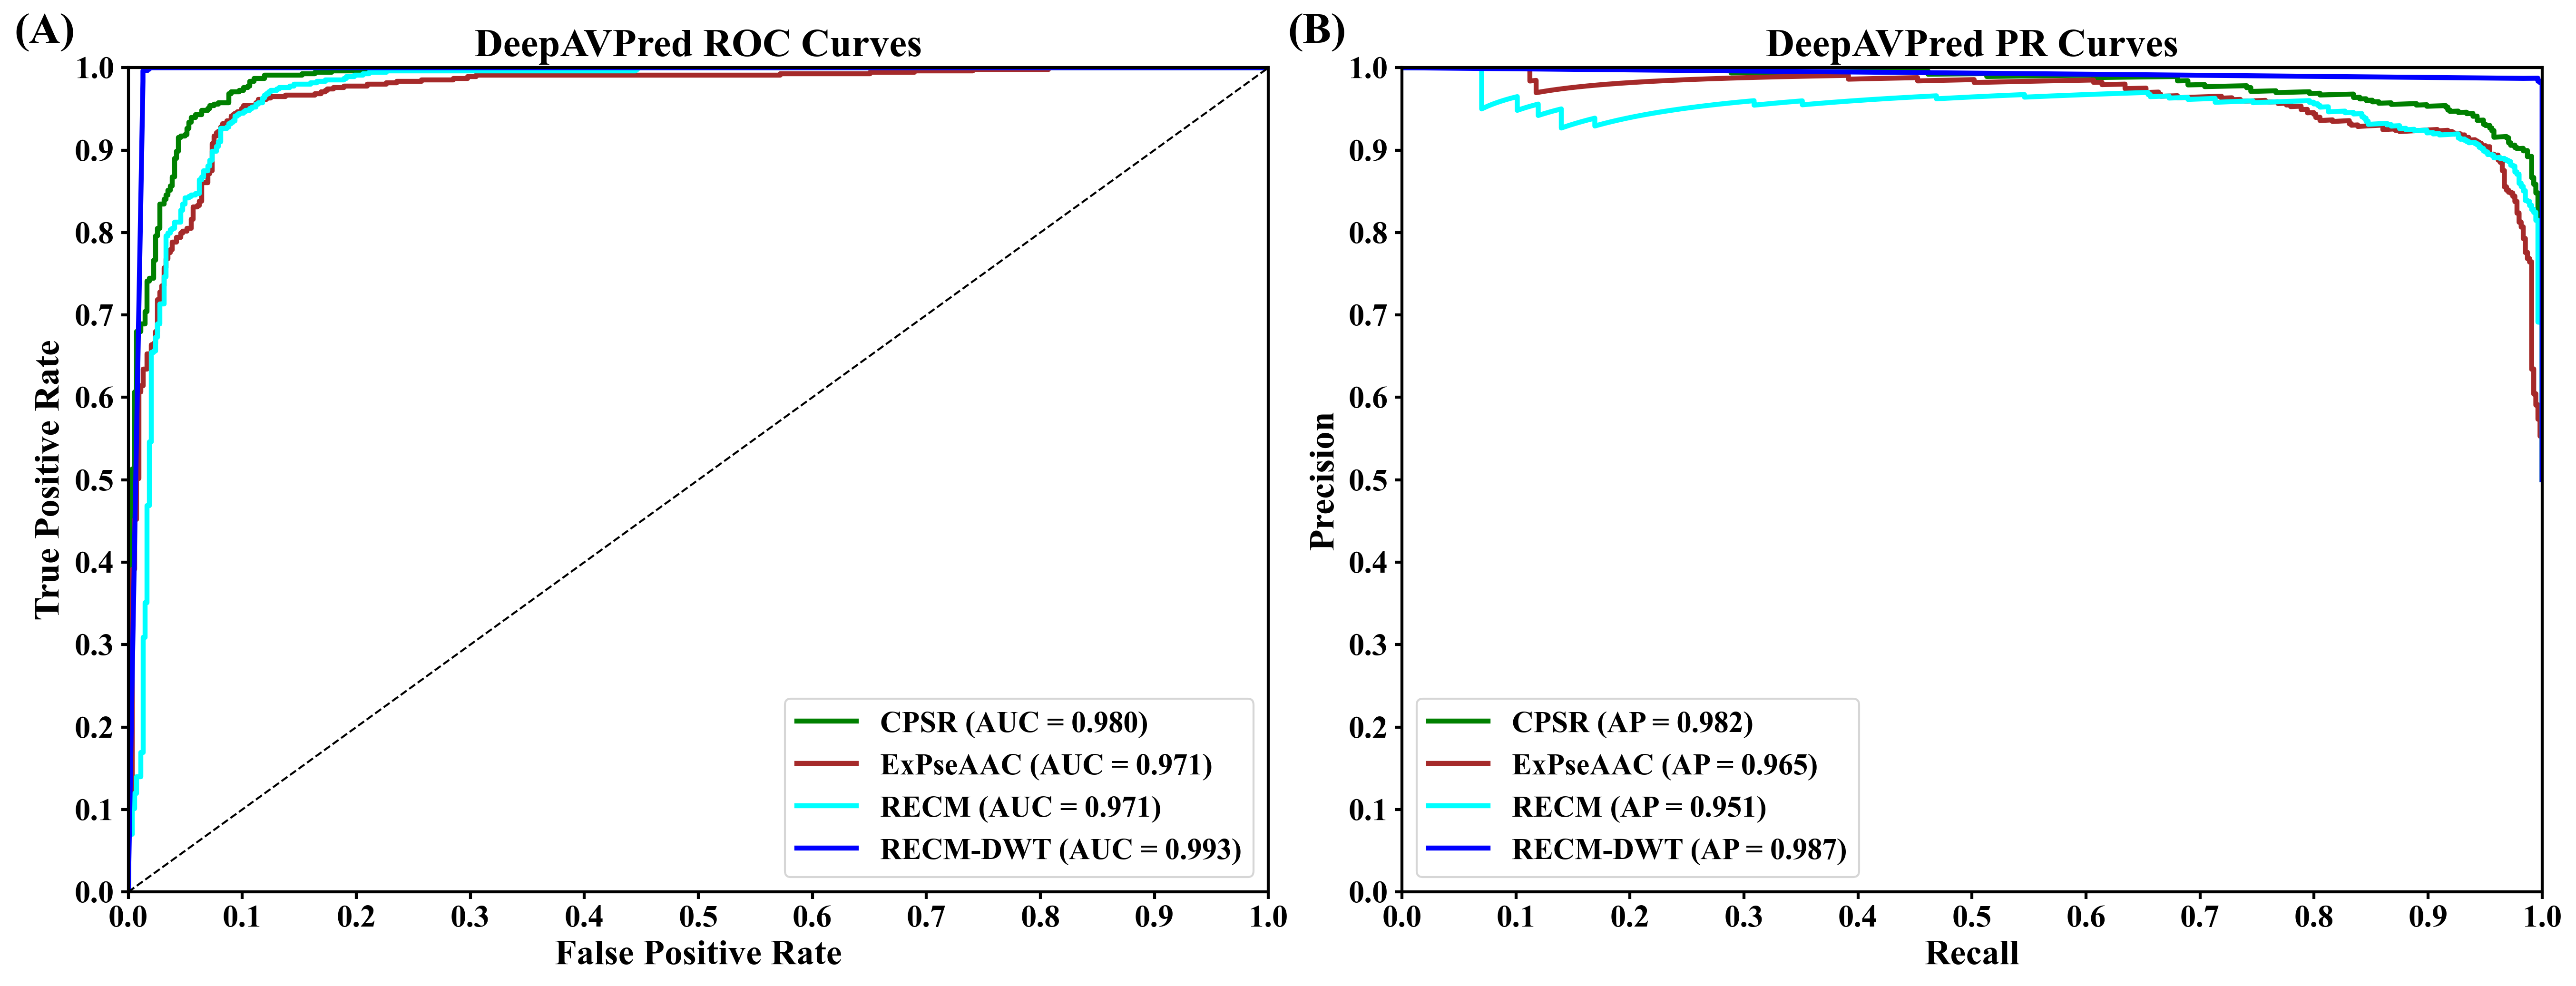

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    roc_curve,
    auc,
    precision_recall_curve,
    average_precision_score
)

# =========================================================
# GLOBAL FONT SETTINGS
# =========================================================

plt.rcParams['font.family'] = 'Times New Roman'
plt.rcParams['font.weight'] = 'bold'

# =========================================================
# LOAD DATA
# =========================================================

def load_data(ytest_file, yscore_file):

    y_test = pd.read_csv(
        ytest_file,
        index_col=0
    ).values.astype(float)

    y_score = pd.read_csv(
        yscore_file,
        index_col=0
    ).values.astype(float)

    return y_test, y_score


# =========================================================
# LOAD AUC
# =========================================================

def load_auc(auc_file, row=10, col=8):

    auc_df = pd.read_csv(
        auc_file,
        index_col=0
    ).values.astype(float)

    if row >= auc_df.shape[0] or col >= auc_df.shape[1]:

        row, col = -1, -1

    return auc_df[row, col]


# =========================================================
# COMPUTE ROC
# =========================================================

def compute_roc(y_test, y_score):

    fpr, tpr, _ = roc_curve(
        y_test[:, 0],
        y_score[:, 0]
    )

    return fpr, tpr


# =========================================================
# COMPUTE PR
# =========================================================

def compute_pr(y_test, y_score):

    precision, recall, _ = precision_recall_curve(
        y_test[:, 0],
        y_score[:, 0]
    )

    ap_score = average_precision_score(
        y_test[:, 0],
        y_score[:, 0]
    )

    return precision, recall, ap_score


# =========================================================
# MAIN
# =========================================================

def main():

    # =====================================================
    # CREATE FIGURE
    # =====================================================

    fig, (ax1, ax2) = plt.subplots(
        1, 2,
        figsize=(18, 7),
        dpi=300
    )

    # =====================================================
    # MODEL FILES
    # =====================================================

    models = [

        (
            'DeepBiGRUytest.csv',
            'DeepBiGRUyscore.csv',
            'DeepBiGRUtrain_results.csv',
            'CPSR',
            'green'
        ),

        (
            'DeepBiGRU_PseAACytest.csv',
            'DeepBiGRU_PseAACyscore.csv',
            'DeepBiGRU_PseAACtrain_results.csv',
            'ExPseAAC',
            'brown'
        ),

        (
            'DeepBiGRU_RECMytest.csv',
            'DeepBiGRU_RECMyscore.csv',
            'DeepBiGRUtrain_results_RECM.csv',
            'RECM',
            'cyan'
        ),

        (
            'DeepBiGRUytest_DWT.csv',
            'DeepBiGRUyscore_DWT.csv',
            'DeepBiGRUtrain_DWT.csv',
            'RECM-DWT',
            'blue'
        )
    ]

    # =====================================================
    # ROC CURVE (A)
    # =====================================================

    for ytest_file, yscore_file, auc_file, label, color in models:

        y_test, y_score = load_data(
            ytest_file,
            yscore_file
        )

        auc_score = load_auc(
            auc_file
        )

        fpr, tpr = compute_roc(
            y_test,
            y_score
        )

        ax1.plot(
            fpr,
            tpr,
            lw=2.5,
            color=color,
            label=f'{label} (AUC = {auc_score:.3f})'
        )

    # Diagonal Line
    ax1.plot(
        [0, 1],
        [0, 1],
        color='black',
        lw=1,
        linestyle='--'
    )

    # Axis Limits
    ax1.set_xlim([0.0, 1.0])
    ax1.set_ylim([0.0, 1.0])

    # Tick Values
    ticks = np.arange(0.0, 1.1, 0.1)

    ax1.set_xticks(ticks)
    ax1.set_yticks(ticks)

    # Tick Font Size
    ax1.tick_params(
        axis='both',
        which='major',
        labelsize=16,
        width=1.5
    )

    # Axis Labels
    ax1.set_xlabel(
        'False Positive Rate',
        fontsize=18,
        fontweight='bold'
    )

    ax1.set_ylabel(
        'True Positive Rate',
        fontsize=18,
        fontweight='bold'
    )

    # Title
    ax1.set_title(
        'DeepAVPred ROC Curves',
        fontsize=20,
        fontweight='bold'
    )

    # Legend
    legend1 = ax1.legend(
        loc="lower right",
        fontsize=15,
        frameon=True
    )

    for text in legend1.get_texts():
        text.set_fontweight('bold')

    # Panel Label
    ax1.text(
        -0.10,
        1.03,
        '(A)',
        transform=ax1.transAxes,
        fontsize=22,
        fontweight='bold'
    )

    # =====================================================
    # PR CURVE (B)
    # =====================================================

    for ytest_file, yscore_file, auc_file, label, color in models:

        y_test, y_score = load_data(
            ytest_file,
            yscore_file
        )

        precision, recall, ap = compute_pr(
            y_test,
            y_score
        )

        ax2.plot(
            recall,
            precision,
            lw=2.5,
            color=color,
            label=f'{label} (AP = {ap:.3f})'
        )

    # Axis Limits
    ax2.set_xlim([0.0, 1.0])
    ax2.set_ylim([0.0, 1.0])

    # Tick Values
    ax2.set_xticks(ticks)
    ax2.set_yticks(ticks)

    # Tick Font Size
    ax2.tick_params(
        axis='both',
        which='major',
        labelsize=16,
        width=1.5
    )

    # Axis Labels
    ax2.set_xlabel(
        'Recall',
        fontsize=18,
        fontweight='bold'
    )

    ax2.set_ylabel(
        'Precision',
        fontsize=18,
        fontweight='bold'
    )

    # Title
    ax2.set_title(
        'DeepAVPred PR Curves',
        fontsize=20,
        fontweight='bold'
    )

    # Legend
    legend2 = ax2.legend(
        loc="lower left",
        fontsize=15,
        frameon=True
    )

    for text in legend2.get_texts():
        text.set_fontweight('bold')

    # Panel Label
    ax2.text(
        -0.10,
        1.03,
        '(B)',
        transform=ax2.transAxes,
        fontsize=22,
        fontweight='bold'
    )

    # =====================================================
    # BORDER WIDTH
    # =====================================================

    for ax in [ax1, ax2]:

        for spine in ax.spines.values():

            spine.set_linewidth(1.5)

    # =====================================================
    # SAVE FIGURE
    # =====================================================

    plt.tight_layout()

    plt.savefig(
        'DeepAVPred_Combined_Figure_HighQuality.svg',
        dpi=2000,
        bbox_inches='tight'
    )

    plt.savefig(
        'DeepAVPred_Combined_Figure_HighQuality.png',
        dpi=600,
        bbox_inches='tight'
    )

    plt.show()


# =========================================================
# RUN
# =========================================================

if __name__ == '__main__':

    main()